In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

df = pd.read_csv("../data/raw/library_occupancy.csv", parse_dates=["timestamp"])
borrow = pd.read_csv("../data/raw/book_borrowing.csv", parse_dates=["date"])
print(df.shape); df.info(); df.head()

(40880, 9)
<class 'pandas.DataFrame'>
RangeIndex: 40880 entries, 0 to 40879
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   timestamp     40880 non-null  datetime64[us]
 1   zone          40880 non-null  str           
 2   capacity      40880 non-null  int64         
 3   occupancy     40676 non-null  float64       
 4   is_weekend    40880 non-null  int64         
 5   is_holiday    40880 non-null  int64         
 6   is_exam       40880 non-null  int64         
 7   is_vacation   40880 non-null  int64         
 8   days_to_exam  40880 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(6), str(1)
memory usage: 3.3 MB


,timestamp,zone,capacity,occupancy,is_weekend,is_holiday,is_exam,is_vacation,days_to_exam
0,2024-07-01 08:00:00,Reading Hall,300,18.0,0,0,0,1,60
1,2024-07-01 09:00:00,Reading Hall,300,27.0,0,0,0,1,60
2,2024-07-01 10:00:00,Reading Hall,300,36.0,0,0,0,1,60
3,2024-07-01 11:00:00,Reading Hall,300,46.0,0,0,0,1,60
4,2024-07-01 12:00:00,Reading Hall,300,52.0,0,0,0,1,60


In [2]:
print("Missing per column:\n", df.isna().sum())
glitch = df["occupancy"] > df["capacity"]
print("Readings above capacity:", glitch.sum())
print(df[glitch].groupby("zone").size())
# missing values by zone and by hour: are they random?
print(df[df.occupancy.isna()].groupby("zone").size())

Missing per column:
 timestamp         0
zone              0
capacity          0
occupancy       204
is_weekend        0
is_holiday        0
is_exam           0
is_vacation       0
days_to_exam      0
dtype: int64
Readings above capacity: 39
zone
Computer Lab         9
Group Discussion    11
Reading Hall        10
Silent Study         9
dtype: int64
zone
Computer Lab        54
Group Discussion    46
Reading Hall        59
Silent Study        45
dtype: int64


In [3]:
d = df.copy()
d.loc[d["occupancy"] > d["capacity"], "occupancy"] = np.nan   # glitches -> NaN
d["rate"] = d["occupancy"] / d["capacity"]
d["hour"] = d["timestamp"].dt.hour
d["dow"] = d["timestamp"].dt.dayofweek
d["month"] = d["timestamp"].dt.month
d["period"] = np.select(
    [d.is_exam == 1, d.is_vacation == 1, d.is_holiday == 1, d.is_weekend == 1],
    ["Exam", "Vacation", "Holiday", "Weekend"], default="Regular")
d.describe()

,timestamp,capacity,occupancy,is_weekend,is_holiday,is_exam,is_vacation,days_to_exam,rate,hour,dow,month
count,40880,40880.000000,40637.000000,40880.000000,40880.000000,40880.000000,40880.000000,40880.000000,40637.000000,40880.000000,40880.000000,40880.000000
mean,2025-07-01 02:30:00,147.500000,51.190516,0.284932,0.017808,0.142466,0.236986,39.945205,0.327252,14.500000,2.993151,6.526027
min,2024-07-01 08:00:00,60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,0.000000,1.000000
25%,2024-12-30 14:45:00,75.000000,12.000000,0.000000,0.000000,0.000000,0.000000,22.000000,0.125000,11.000000,1.000000,4.000000
50%,2025-07-01 02:30:00,115.000000,31.000000,0.000000,0.000000,0.000000,0.000000,45.000000,0.260000,14.500000,3.000000,7.000000
75%,2025-12-30 14:15:00,187.500000,69.000000,1.000000,0.000000,0.000000,0.000000,60.000000,0.512500,18.000000,5.000000,10.000000
max,2026-06-30 21:00:00,300.000000,300.000000,1.000000,1.000000,1.000000,1.000000,60.000000,1.000000,21.000000,6.000000,12.000000
std,NaN,94.175193,54.147009,0.451387,0.132255,0.349531,0.425239,20.166603,0.241390,4.031178,2.001724,3.447893


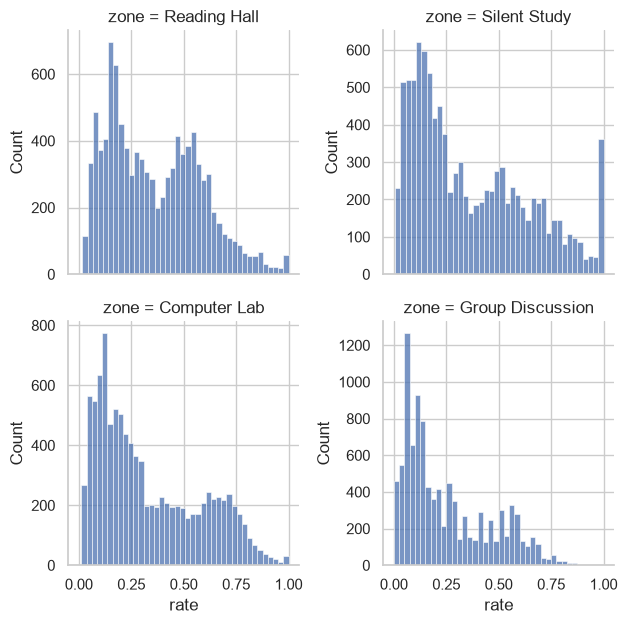

Share of hours above 70% full:
 zone
Computer Lab        0.106
Group Discussion    0.021
Reading Hall        0.070
Silent Study        0.144
Name: rate, dtype: float64


In [4]:
g = sns.FacetGrid(d, col="zone", col_wrap=2, height=3.2, sharey=False)
g.map(sns.histplot, "rate", bins=40)
save("eda_rate_distribution")
print("Share of hours above 70% full:\n", (d.rate > 0.7).groupby(d.zone).mean().round(3))

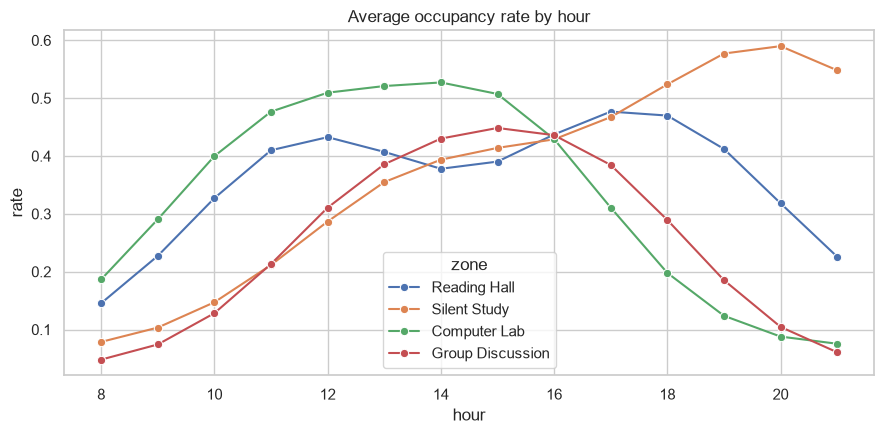

In [5]:
plt.figure(figsize=(9, 4.5))
sns.lineplot(data=d, x="hour", y="rate", hue="zone", errorbar=None, marker="o")
plt.title("Average occupancy rate by hour"); save("eda_hourly_profile")

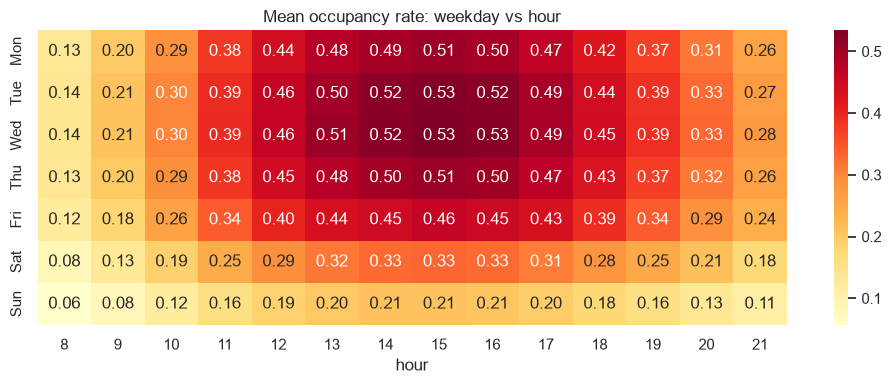

In [6]:
pivot = d.pivot_table(index="dow", columns="hour", values="rate", aggfunc="mean")
pivot.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.figure(figsize=(10, 4)); sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".2f")
plt.title("Mean occupancy rate: weekday vs hour"); save("eda_heatmap")

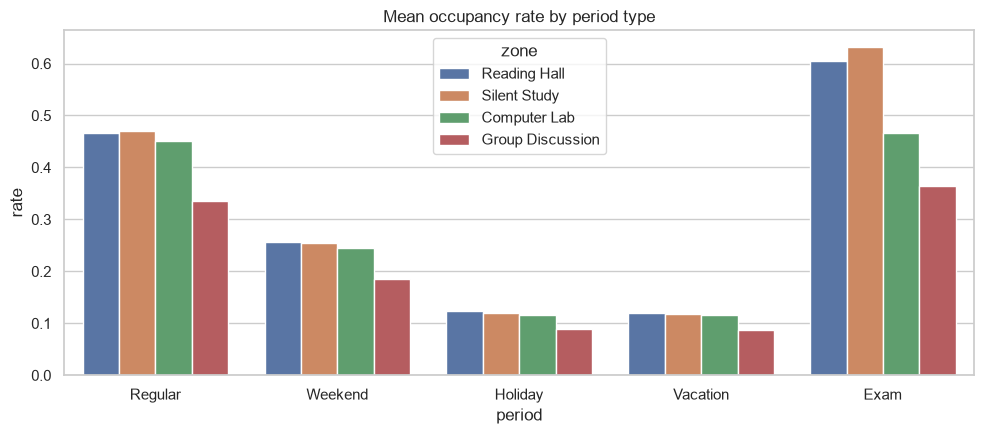

In [7]:
order = ["Regular", "Weekend", "Holiday", "Vacation", "Exam"]
plt.figure(figsize=(10, 4.5))
sns.barplot(data=d, x="period", y="rate", hue="zone", order=order, errorbar=None)
plt.title("Mean occupancy rate by period type"); save("eda_period_effect")

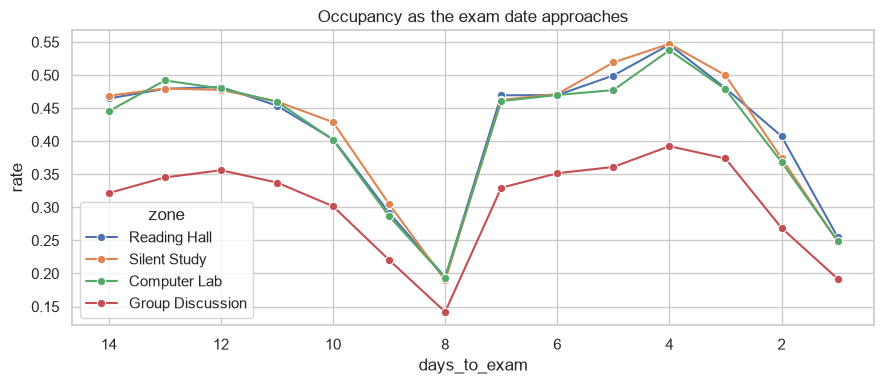

In [8]:
ramp = d[(d.is_exam == 0) & (d.is_vacation == 0) & (d.days_to_exam <= 14)]
plt.figure(figsize=(9, 4))
sns.lineplot(data=ramp, x="days_to_exam", y="rate", hue="zone", errorbar=None, marker="o")
plt.gca().invert_xaxis(); plt.title("Occupancy as the exam date approaches")
save("eda_pre_exam_ramp")

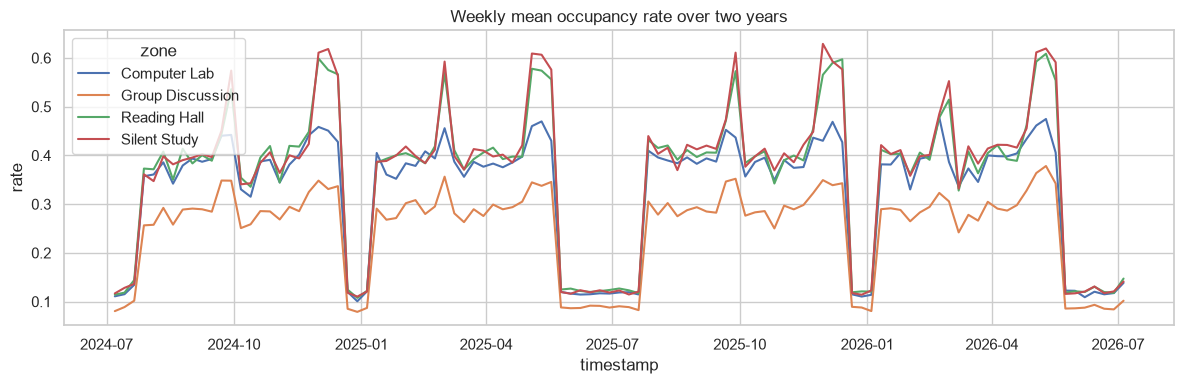

In [9]:
weekly = d.set_index("timestamp").groupby("zone")["rate"].resample("W").mean().reset_index()
plt.figure(figsize=(12, 4))
sns.lineplot(data=weekly, x="timestamp", y="rate", hue="zone")
plt.title("Weekly mean occupancy rate over two years"); save("eda_weekly_trend")

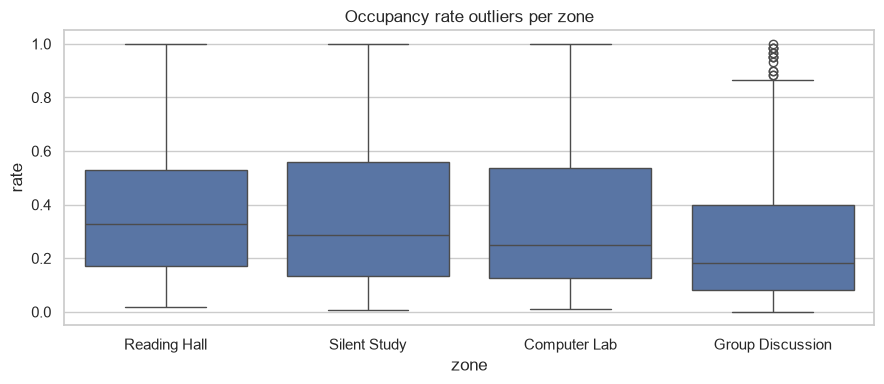

Days with unusually low or high use (z-score > 3):
zone
Computer Lab        0
Group Discussion    0
Reading Hall        0
Silent Study        0
dtype: int64


In [10]:
plt.figure(figsize=(9, 4)); sns.boxplot(data=d, x="zone", y="rate")
plt.title("Occupancy rate outliers per zone"); save("eda_outliers")
daily = d.groupby([d.timestamp.dt.date, "zone"])["rate"].mean().unstack()
print("Days with unusually low or high use (z-score > 3):")
z = (daily - daily.mean()) / daily.std()
print((z.abs() > 3).sum())

In [11]:
one = d[d.zone == "Reading Hall"].set_index("timestamp")["rate"]
for lag in [1, 2, 24, 168]:
    print(f"lag {lag:>3}: corr = {one.corr(one.shift(lag)):.3f}")

lag   1: corr = 0.932
lag   2: corr = 0.798
lag  24: corr = 0.296
lag 168: corr = 0.326


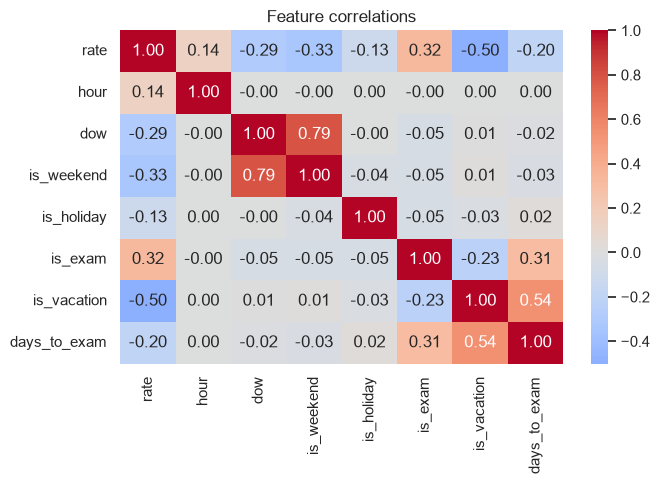

In [12]:
cols = ["rate", "hour", "dow", "is_weekend", "is_holiday", "is_exam", "is_vacation", "days_to_exam"]
plt.figure(figsize=(7, 5)); sns.heatmap(d[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlations"); save("eda_correlation")

In [13]:
d["is_peak"] = (d.rate >= 0.70).astype(int)
print(d.is_peak.value_counts(normalize=True).round(3))
print(d.groupby("zone").is_peak.mean().round(3))

is_peak
0    0.909
1    0.091
Name: proportion, dtype: float64
zone
Computer Lab        0.117
Group Discussion    0.025
Reading Hall        0.071
Silent Study        0.150
Name: is_peak, dtype: float64


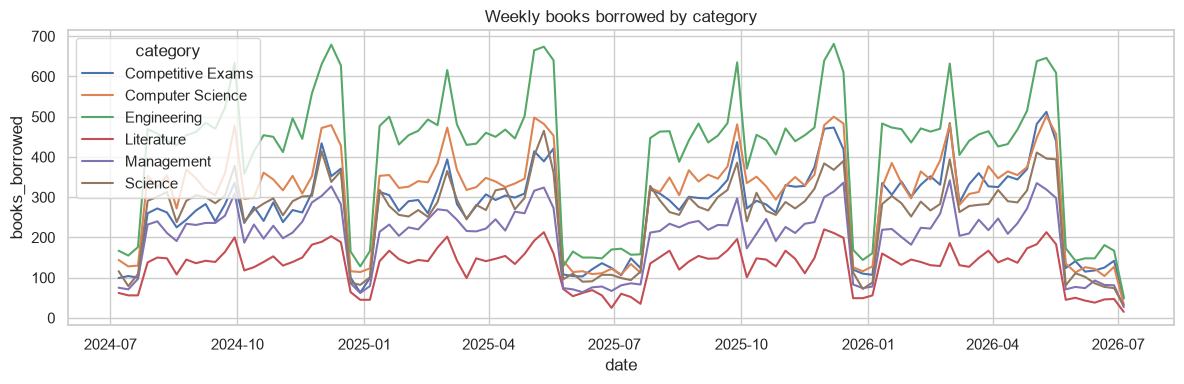

In [14]:
w = borrow.set_index("date").groupby("category")["books_borrowed"].resample("W").sum().reset_index()
plt.figure(figsize=(12, 4)); sns.lineplot(data=w, x="date", y="books_borrowed", hue="category")
plt.title("Weekly books borrowed by category"); save("eda_borrowing")